In [ ]:
import requests
import re
from bs4 import BeautifulSoup
import xml.etree.ElementTree as ET
import pandas as pd
import time
import json
import pandas as pd
from google import genai
from google.genai import types
import time
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
import chromadb
import json
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase
import os

### 1. Scraping all the book summaries

As I am using only the first four books in this experiment, I just copied the link-endings by hand instead of scaping them.

In [33]:
books = ["Pretty_Little_Liars_(Book)",
        "Flawless",
        "Perfect",
        "Unbelievable"]

In [ ]:
def parse_summary(page):
    url = f"https://prettylittleliars.fandom.com/api.php?action=parse&page={page}&format=xml"
    print(url)
    response = requests.get(url)
    root = ET.fromstring(response.text)
    parse = root.find("parse")
    text_elem = parse.find("text")
    html = text_elem.text
    soup = BeautifulSoup(html, "html.parser")

    h2_first = soup.find(id="Plot")
    h2_last = soup.find(id="Chapters").parent

    ps_between = []
    for node in h2_first.parent.next_siblings:
        if getattr(node, "name", None) is None:
            continue
        if node is h2_last or (hasattr(node, "name") and node.name == "h2" and node == h2_last):
            break
        # Only appending <p> tags to skip images
        if node.name == "p":
            ps_between.append(node)

    ps_between_texts = [p.get_text(" ", strip=True) for p in ps_between]
    # removing /n from the text for easier readability
    final_string = re.sub(r"/n", "", " ".join(ps_between_texts), flags=re.DOTALL | re.MULTILINE)
    return final_string

This is pretty much the same as the summary parser for the series episodes, except that the h2 tags have slightly different id-names.

In [36]:
book_dicts = []
for book in books:
    d = {"title": ("Pretty Little Liars" if book == "Pretty_Little_Liars_(Book)" else book), "summary": parse_summary(book)}
    book_dicts.append(d)
    time.sleep(3)

https://prettylittleliars.fandom.com/api.php?action=parse&page=Pretty_Little_Liars_(Book)&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Flawless&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Perfect&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Unbelievable&format=xml


### 2. The final data

In [37]:
df = pd.DataFrame(book_dicts)
df

,title,summary
0,Pretty Little Liars,"In Rosewood , Pennsylvania , Alison ""Ali"" DiLa..."
1,Flawless,"Spencer Hastings, Hanna Marin, Aria Montgomery..."
2,Perfect,
3,Unbelievable,Emily returns home when she sees her parents o...


As you can see, he website is missing a summary for the book "perfect", so I decided to replace it with a summary from <a href="https://www.reddit.com/r/PrettyLittleLiars/comments/164ufng/a_breakdown_of_the_pll_books_14/"> this </a> reddit post.

In [38]:
df.loc[df["title"] == "Perfect", "summary"] = """We open with a flashback of before Ali died. The girls are playing around pretending to be on a talk show while Aria films them. There is some tension between Spencer and Ali, and Ali and Aria. Ali is acting weird and getting texts and the girls try to read them when she leaves the room, but she catches them. Melissa and Ian enter and Ian decides to play with them and Spencer “interviews” him.

Spencer starts seeing the same therapist as Melissa, and she enjoys having someone take her side and not always side with Melissa the way her parents do. She is also nominated for a prestigious award called The Golden Orchid but is nominated for “her” essay, which is actually Melissa’s.

Mona and Hanna make plans for their “Frenniversary” which Hanna ends up having to miss as Wilden shows up at her house to ask her and the other girls more questions after the video of them pretending to be on a talk show is sent to the press. This causes Mona to get really angry at Hanna.

Ian is back again, dating Melissa. He is also Spencer’s field hockey coach which I forgot to mention earlier but he becomes more important in this book.

Ella kind of kicks Aria out of the house, and she ends up living with Sean for a big part of the book.

Emily wants to tell Wilden about A, so A posts pictures of Emily and Maya kissing during a school swim meet, and the entire school, plus her parents see them. Her parents are homophobic and want to send Emily to a conversion camp called Tree Tops (although they don’t call it that), and say that if she refuses to go to the camp and “undo the gay” (not a direct quote), they will send her off to live with overly strict aunt and uncle in Iowa.

There is also a subplot about a “Rosewood Stalker” in this book, but by the end of book 4, it is unclear whether that person was A or not (unless I somehow missed that in the reveal??)

Mona starts hanging out with Naomi and Rylie and they are kind of ditching Hanna, and leave her to pay their bill where she strikes up a conversation with the waiter, who is Lucas Beattie. Hanna gets an A text telling her that Mona isn’t really her friend. During this time, Mona is also planning her “sweet seventeen” party, which only Hanna was supposed to be part of, but she’s added Naomi and Rylie.

Emily meets with a girl who did the Tree Tops program and realizes that it didn’t work, and decides to meet with Maya again during Mona’s party, and her mom catches them.

Spencer does a photoshoot/interview for the Philidelphia Sentinel where she will be on the cover with her Golden Orchid announcement.

Mona disinvites Hanna from her party after Hanna hires someone to write “Get ready to party with Mona” in the sky, and they end up writing “Get ready to fart with Mona” instead (lmao).

Spencer is having trouble remembering parts of the night that Ali went missing, and tries hypnosis which unlocks part of the memories and makes her think that she killed Ali. She asks her parents if she’s ever had memory loss and they tell her it happened once when she got really sick, but Spencer is scared that she did something to Ali.

Hanna is being made fun of at school now, and starting hanging out with Lucas. They go on a cute non-date in a hot air balloon and she tells him about A and about her bulimia, he tells her that his brother tried to kill himself and they end up kissing. Hanna also gets a new phone because no one is texting her so she thinks her old phone is broken (lol). She doesn’t transfer her data over (this is relevant later). She also gets a text from A telling her that Mona got lipo.

Aria tells Ezra about the drama with her parents, and they kiss, A sees.

Melissa gets a text with her essay, which she reads out loud. Her dad says that is Spencer’s essay, and they realize what Spencer did. The two fight, and in a fit of rage, Spencer pushes Melissa down the stairs. Afterward, she is locked in her room for safety.

Aria is hanging out at Ezra’s place where they have just had sex. Cops come to his door and arrest him (fucking finally). Turns out A sent Sean the pictures of Aria and Ezra, and Sean went to the cops. He kicks Aria out of his house and she ends up going to stay with Byron and Meredith.

Hanna gets a package with the dress that she was supposed to wear to Mona’s party, and assumes that this means Mona has forgiven her. She wears the dress, which fits her way too small and shows up at the party, where Mona confronts her. Turns out Mona changed the dresses and didn’t tell Hanna (who was still uninvited). Hanna’s dress rips in front of everyone and Mona, Naomi, and Rylie make fun of her. Hanna makes a comment about Mona’s lipo, which turns out to not be true. Lucas saves Hanna from being humiliated and gives her clothes to change into. When going home, Hanna gets an A text, only this one is not sent from a blocked number. A has fucked up and sent the text from their actual number, which Hanna recognizes. She calls the girls and asks them to meet her.

Aria thinks Ian killed Ali as she rewatches the video of them from the flashback, and notices Ali and Ian holding/touching hands in the background.

While Hanna waits for the girls to show up she is run over by an SUV. Her phone is completely destroyed. The girls get the “She knew too much” text.
"""

In [39]:
df

,title,summary
0,Pretty Little Liars,"In Rosewood , Pennsylvania , Alison ""Ali"" DiLa..."
1,Flawless,"Spencer Hastings, Hanna Marin, Aria Montgomery..."
2,Perfect,We open with a flashback of before Ali died. T...
3,Unbelievable,Emily returns home when she sees her parents o...


In [40]:
df.to_csv('PrettyLittleLiars_Books.csv', index=False)

### 4. Extract entities and relationships

In [ ]:
client = genai.Client(api_key="MY_API_KEY")

In [ ]:
prompt = """
            You are an entity-relationship extractor.
            Extract ALL explicitly mentioned entities in the text and their relationships with one another.

            Rules:
            Extract ALL explicitly mentioned entities and relationships.
            Entities can ONLY be Groups or Characters.
            Each entity has FIELDS: name, aliases, description (not empty).
            Each relationship has FIELDS: source, target, type, evidence (not empty).
            Descriptions MUST be at least one sentence → summarize from the text.
            Evidence MUST directly quote text passages (max. 150 characters).
            Evidence is the decisive text snippet that supports the relationship.
            If "A" is mentioned, always extract A under the name "A".
            If the interaction is neutral, minimal, or ambiguous, do NOT extract a relationship at all.
            Only choose between the given relationship types.

            Relationship types: ENGAGED | FRIEND | FAMILY | SIBLING | STEP-SIBLING | PARENT | CHILD | DATED | MARRIED | BLACKMAILED | ALLIED

            Output as JSON, no explanation:
            {
            "entities": [{ "type": "Character", "name": "...", "aliases": [], "description": "..." }, ...],
            "relationships": [{ "source": "...", "target": "...", "type": "...", "evidence": "..." }, ...]
            }
           
        """

Originally I tried to use local LLMS through Ollama, but not only did that take up a significant amount of times, the LLMs were also ususally too small to properly follow the rules and understanding the concepts of relatinships, so I had to use AIStudio instead.

In [ ]:
for index, book in df.iterrows():
    print(book["title"])
    print(book["summary"])
    response = client.models.generate_content(
        model="gemini-3.1-flash-lite",
        #model="gemma-4-26b-a4b-it",
        contents=f"""{prompt}

                Extract from the following passage:

                {book["summary"]}
                """,
        config=types.GenerateContentConfig(
            temperature=0.1,
            response_mime_type="application/json",
        ),
)
    print(response.text)

    json_file = json.loads(response.text)
    for entity in json_file["relationships"]:
        entity["book"]=index+1

    rel_path = "relationships.json"
    with open(rel_path, "a", encoding="utf-8") as f:
        json.dump(json_file["relationships"], f, ensure_ascii=False, indent=2)

    char_path = "entities.json"
    with open(char_path, "a", encoding="utf-8") as f:
        json.dump(json_file["entities"], f, ensure_ascii=False, indent=2)
    time.sleep(7)
        


Pretty Little Liars
In Rosewood , Pennsylvania , Alison "Ali" DiLaurentis is the beautiful and manipulative queen bee of Rosewood Day , ruling the school with her four best friends: Aria Montgomery , a quirky and artistic girl who feels out of place; Hanna Marin , a chubby girl who wishes she were just like Ali; Emily Fields , a shy swimmer who secretly has a crush on Ali; and Spencer Hastings , an extreme perfectionist who sometimes butts heads with Ali. The five have an end-of-seventh-grade sleepover, during which Ali disappears in the middle of the night. The story then jumps three years later, when the girls are living their own lives and don't speak to each other anymore. Aria returns to Rosewood from a three year trip to Iceland with her family and comes back much more sophisticated than before she left. She meets and kisses a guy in a local bar who is later revealed to be her English teacher, Ezra Fitz . Emily befriends the new girl in town, Maya St. Germain , and soon develops 

### 5. Cleaning the extracted data

This function normalizes the names of entities and relationships, as some Characters have different names in the books and series, different arrays are needed for each.

In [ ]:
aliases_book = {
    "Ali": "Alison DiLaurentis",
    "Alison": "Alison DiLaurentis",
    "Ezra": "Ezra Fitz",
    "Mr. Fitz": "Ezra Fitz",
    "Hanna": "Hanna Marin",
    "Emily": "Emily Fields",
    "Aria": "Aria Montgomery",
    "Spencer": "Spencer Hastings",
    "Maya": "Maya St. Germain",
    "Melissa": "Melissa Hastings",
    "Wren": "Wren Kim",
    "Jessica": "Jessica DiLaurentis",
    "Toby": "Toby Cavanaugh",
    "Jenna": "Jenna Marshall",
    "Wilden": "Darren Wilden",
    "Detective Wilden": "Darren Wilden",
    "Sean": "Sean Ackard",
    "Ben": "Ben Coogan",
    "Mona": "Mona Vanderwaal",
    "Meredith": "Meredith Succi",
    "Byron": "Byron Montgomery",
    "Ella": "Ella Montgomery",
    "Veronica": "Veronica Hastings",
    "Isabel": "Isabel Marin",
    "Amber": "Amber Victorino",
    "Peter": "Peter Hastings",
    "Andrew": "Andrew Newhoff",
    "Alex": "Alex Santiago",
    "Lucas": "Lucas Gottesman",
    "Ashley": "Ashley Marin",
    "Mike": "Mike Montgomery",
    "Toby Walker": "Toby Cavanaugh",
    "Toby Marshall": "Toby Cavanaugh",
    "Holden": "Holden Strauss",
    "The girls' clique": "The Liars",
    "The girls": "The Liars",
    "The Clique": "The Liars",
    "Pretty Little Liars": "The Liars",
    "The Liars (again)": "The Liars",
    "The Liars' Clique": "The Liars",
    "Paige": "Paige McCullers",
    "Paige McCullough": "Paige McCullers",
    "Officer Garrett Reynolds": "Garrett Reynolds",
    "Garrett": "Garrett Reynolds",
    "Dr. Anne Sullivan": "Dr. Sullivan",
    "Hanna Marin's father (Tom)": "Tom Marin",
    "the Marins": "The Marin Family",
    "the Fields' family": "The Fields Family",
    "Dr. Amanda Sullivan": "Dr. Sullivan",
    "Hanna Marin's father": "Tom Marin",
    "Holden": "Holden Straussberg",
    "Officer Wilden": "Darren Wilden", 
    "Wren Kingston": "Wren Kim",
    "Rylie": "Riley Wolfe",
    "Riley": "Riley Wolfe",
    "Trista": "Trista Taylor",
    "Ali (Alison)": "Alison DiLaurentis",
    "Ian": "Ian Thomas",
    "Noel": "Noel Kahn",
    "Andrew": "Andrew Campbell",
    "Andrew Newhoff": "Andrew Campbell",

    "FRIEND_OF": "FRIEND",
    "DATER_OF": "DATED",
    "DATING": "DATED",
    "LOVER_OF": "LOVES",
    "BLACKMAILED_BY": "BLACKMAILED",
    
}

aliases_series = {
    "Ali": "Alison DiLaurentis",
    "Alison": "Alison DiLaurentis",
    "Ezra": "Ezra Fitz",
    "Mr. Fitz": "Ezra Fitz",
    "Hanna": "Hanna Marin",
    "Emily": "Emily Fields",
    "Aria": "Aria Montgomery",
    "Spencer": "Spencer Hastings",
    "Maya": "Maya St. Germain",
    "Melissa": "Melissa Hastings",
    "Wren": "Wren Kingston",
    "Jessica": "Jessica DiLaurentis",
    "Toby": "Toby Cavanaugh",
    "Jenna": "Jenna Marshall",
    "Wilden": "Darren Wilden",
    "Detective Wilden": "Darren Wilden",
    "Sean": "Sean Ackard",
    "Ben": "Ben Coogan",
    "Mona": "Mona Vanderwaal",
    "Meredith": "Meredith Succi",
    "Byron": "Byron Montgomery",
    "Ella": "Ella Montgomery",
    "Veronica": "Veronica Hastings",
    "Isabel": "Isabel Marin",
    "Amber": "Amber Victorino",
    "Peter": "Peter Hastings",
    "Andrew": "Andrew Newhoff",
    "Alex": "Alex Santiago",
    "Lucas": "Lucas Gottesman",
    "Ashley": "Ashley Marin",
    "Mike": "Mike Montgomery",
    "Toby Walker": "Toby Cavanaugh",
    "Toby Marshall": "Toby Cavanaugh",
    "Holden": "Holden Strauss",
    "The girls' clique": "The Liars",
    "The girls": "The Liars",
    "The Clique": "The Liars",
    "Pretty Little Liars": "The Liars",
    "The Liars (again)": "The Liars",
    "The Liars' Clique": "The Liars",
    "Paige": "Paige McCullers",
    "Paige McCullough": "Paige McCullers",
    "Officer Garrett Reynolds": "Garrett Reynolds",
    "Garrett": "Garrett Reynolds",
    "Dr. Anne Sullivan": "Dr. Sullivan",
    "Hanna Marin's father (Tom)": "Tom Marin",
    "the Marins": "The Marin Family",
    "the Fields' family": "The Fields Family",
    "Dr. Amanda Sullivan": "Dr. Sullivan",
    "Hanna Marin's father": "Tom Marin",
    "Holden": "Holden Straussberg",
    "Officer Wilden": "Darren Wilden",
    "Officer Darren Wilden": "Darren Wilden",
    "The girls (Aria Montgomery, Spencer Hastings, Hanna Marin, Emily Fields)": "The Liars",
    "Dr. Wren Kingston": "Wren Kingston",
    "Caleb": "Caleb Rivers",
    "Alex Wolf": "Alex Santiago",
    "The Police": "The Rosewood Police Force",
    "Ian": "Ian Thomas",
    "Jackie": "Jackie Molina",
    "Darren": "Darren Wilden",
    "Noel": "Noel Kahn",
    "Andrew": "Andrew Campbell",
    "Andrew Newhoff": "Andrew Campbell",

    "FRIEND_OF": "FRIEND",
    "DATER_OF": "DATED",
    "DATING": "DATED",
    "LOVER_OF": "LOVES",
    "BLACKMAILED_BY": "BLACKMAILED", 
}

def normalize(name, type):
    if type == "book":
        return aliases_book.get(name, name)
    if type == "series":
        return aliases_series.get(name, name)

First the entities are cleaned by 
1. normalizing the names 
2. merging two instances of the same character into one.

In [ ]:
seen = {}

with open("entities.json", "r", encoding="utf-8") as f:
    entities = json.load(f)
    
    for entity in entities:
        entity["name"] = normalize(entity["name"], "book")
        if entity["name"] not in seen:
            seen[entity["name"]] = entity.copy()
            seen[entity["name"]]["description"] = [seen[entity["name"]]["description"]]
        else:
            existing_entity = seen[entity["name"]]
            if entity["description"] not in existing_entity["description"]:
                existing_entity["description"].append(entity["description"])

with open("entities_cleaned.json", "w", encoding="utf-8") as f:
    json.dump(list(seen.values()), f, ensure_ascii=False, indent=2)

Secondly, the entities are cleaned by 
1. normalizing the names
2. merging two instances of the relationship into one as long as there is no different relationship type in between (in case of changing of relationships. For example Spencer and Emily can first be friends, then get into a fight, become enemies and then can go back to friends. In that case you would not want the two instances of them being friends to merge.)

In [ ]:
relationships_cleaned = []
with open("relationships.json", "r", encoding="utf-8") as f:
    book_relationships = json.load(f)
    sources = []
    for rel in book_relationships:
        if rel["source"] not in sources:
            sources.append(rel["source"])

    for source in sources:
        source_relationships = []
        for rel in book_relationships:
            rel["type"] = normalize(rel["type"], "book")
            rel["source"] = normalize(rel["source"], "book")
            rel["target"] = normalize(rel["target"], "book")
            if source == rel["source"]:
                last_rel = None
                last_rel_index = None

                for i in range(len(source_relationships) - 1, -1, -1):
                    if (source_relationships[i]["source"] == rel["source"] and source_relationships[i]["target"] == rel["target"]):
                        last_rel = source_relationships[i]
                        last_rel_index = i
                        break

                if last_rel and (last_rel["source"] == rel["source"] and last_rel["target"] == rel["target"] and last_rel["type"] == rel["type"]):
                    if not isinstance(source_relationships[last_rel_index]["evidence"], list):
                        source_relationships[last_rel_index]["evidence"] = [source_relationships[last_rel_index]["evidence"]]
                    source_relationships[last_rel_index]["evidence"].append(rel["evidence"])
                else:
                    source_relationships.append(rel)

        for s_rel in source_relationships:
            s_rel["source"] = normalize(s_rel["source"], "series")
            s_rel["target"] = normalize(s_rel["target"], "series")
            s_rel["type"] = normalize(s_rel["type"], "series")
            relationships_cleaned.append(s_rel)
    
with open("relationships_cleaned.json", "w", encoding="utf-8") as f:
    json.dump(list(relationships_cleaned), f, ensure_ascii=False, indent=2)

### 6. Visualizing the graph
(This is not really needed, I just thought it would save you the hassle of creating an instance of a neo4j database just to look at the graph)

In [ ]:
G = nx.DiGraph()

In [ ]:
with open("entities_api_cleaned.json", "r", encoding="utf-8") as f:
    entities = json.load(f)

    for ent in entities:
        if ent["type"] == "Character":
            G.add_node(
                ent["name"],
                entity_type=ent.get("type"))

with open("relationships_api_cleaned.json", "r", encoding="utf-8") as f:
    relationships = json.load(f)

for rel in relationships:
    source = rel["source"]
    target = rel["target"]

    if not G.has_node(source):
        G.add_node(source, entity_type="Character")
    if not G.has_node(target):
        G.add_node(target, entity_type="Character")

    G.add_edge(
        source,
        target,
        relation=rel.get("type")
    )

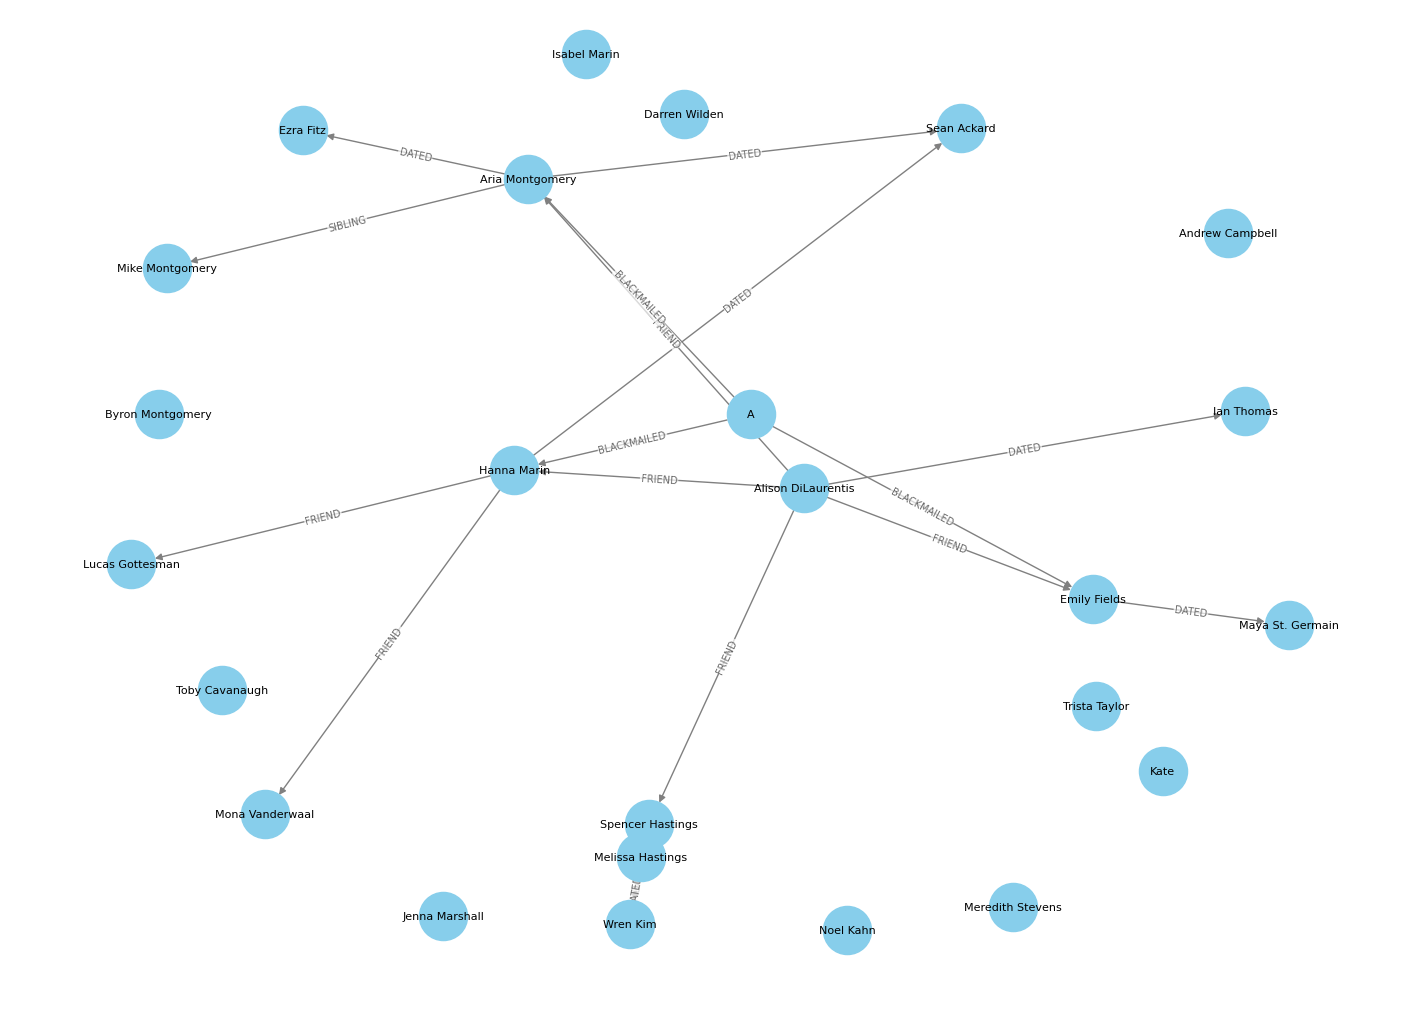

In [ ]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1200,
    node_color="skyblue",
    edge_color="gray",
    font_size=8,
    arrows=True
)

edge_labels = {(u, v): d.get("relation", "NO LABEL") or d.get("label", "NO LABEL") for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_color="dimgray",
    font_size=7,
    rotate=True,
    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7)
)

plt.axis("off")
plt.show()

As you can see, unfortunately some of the nodes do not have any edges. Further there are some nodes missing, for example most of the parents. I suppose with a better model, more entities and relationships could have been extracted.

### 7. Adding the data to the graph database

In [ ]:
URI = "bolt://localhost:7687"
USER = os.getenv("NEO_USER", "neo4j")
PASSWORD = os.getenv("NEO_PASSWORD", "password")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

In [ ]:
with open("entities_api_cleaned.json", "r", encoding="utf-8") as f:
    entities = json.load(f)
    
characters = [e for e in entities if e["type"] == "Character"]
groups = [e for e in entities if e["type"] == "Group"]

query_characters = """
UNWIND $rows AS row
MERGE (c:Character {name: row.name})
SET c.type = row.type,
    c.aliases = coalesce(row.aliases, []),
    c.description = [x IN coalesce(row.description, []) WHERE x IS NOT NULL AND trim(x) <> ""]
"""

query_groups = """
UNWIND $rows AS row
MERGE (g:Group {name: row.name})
SET g.type = row.type,
    g.aliases = coalesce(row.aliases, []),
    g.description = [x IN coalesce(row.description, []) WHERE x IS NOT NULL AND trim(x) <> ""]
"""

with driver.session(database="books") as session:
    if characters:
        session.run(query_characters, rows=characters)
    if groups:
        session.run(query_groups, rows=groups)

driver.close()

In [ ]:
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

with open("relationships_api_cleaned.json", "r", encoding="utf-8") as f:
    relationships = json.load(f)

query = """
UNWIND $rows AS row
MATCH (source {name: row.source})
MATCH (target {name: row.target})
MERGE (source)-[r:RELATED_TO {
    type: row.type,
    book: row.book
}]->(target)
SET r.evidence = row.evidence
"""

with driver.session(database="books") as session:
    session.run(query, rows=relationships)

driver.close()

### 8. Creating the Vector Database

In [ ]:
model = SentenceTransformer("microsoft/harrier-oss-v1-270m")
df = pd.read_csv("PrettyLittleLiars_Books.csv")

[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'sliding_attention', 'full_attention'}
Loading weights: 100%|██████████| 236/236 [00:00<00:00, 3377.26it/s]
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'sliding_attention', 'full_attention'}
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'sliding_attention', 'full_attention'}


In the following example I am using ChromaDB as we had previously used ChromaDB in the Application Project. I do not believe that the choice of vector database is of significance in this application.  I am creating a seperate collections for the book vectors and the series vectors.

In [ ]:
client = chromadb.PersistentClient(path="../chroma_db")
collection = client.get_or_create_collection(
    name="books",
    metadata={"hnsw:space": "cosine"})

In [ ]:
documents = []
embeddings = []
metadatas = []
ids = []

for book_idx, book in df.iterrows():
    print(book["title"])
    print(book["summary"][:200])

    # Splitting the text into chunk
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=512, chunk_overlap=50)
    chunks = text_splitter.split_text(book["summary"])
    for chunk_idx, chunk in enumerate(chunks):
        chunk_id = f"book_{book_idx}_chunk_{chunk_idx}"

        documents.append(chunk)
        # enmbedding each chunk to a vector
        embeddings.append(model.encode(chunk).tolist())
        # adding relevant metadata
        metadatas.append({
            "title": book["title"],
            "book_index": int(book_idx),
            "chunk_index": chunk_idx
        })
        ids.append(chunk_id)

collection.add(
    ids=ids,
    documents=documents,
    embeddings=embeddings,
    metadatas=metadatas
)

Pretty Little Liars
In Rosewood , Pennsylvania , Alison "Ali" DiLaurentis is the beautiful and manipulative queen bee of Rosewood Day , ruling the school with her four best friends: Aria Montgomery , a quirky and artisti
Flawless
Spencer Hastings, Hanna Marin, Aria Montgomery, and Emily Fields continue to receive text messages from an unknown person, "A", and are more desperate than ever to discover their identity. "A" continu
Perfect
We open with a flashback of before Ali died. The girls are playing around pretending to be on a talk show while Aria films them. There is some tension between Spencer and Ali, and Ali and Aria. Ali is
Unbelievable
Emily returns home when she sees her parents on TV, who tell her that they love her and accept her for who she is. Mona and Hanna's friendship is restored, and to celebrate Hanna's recovery, Mona and 
